<a href="https://colab.research.google.com/github/dexter-llabCD/Dexter_activity_01_AI.ipynb/blob/main/Brigole_Dexter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Educational Guide: Demystifying K-Nearest Neighbors (KNN)

This notebook walks through the key aspects of the K-Nearest Neighbors algorithm, exploring how features, normalization, hyperparameters, and cross-validation affect both classification and regression performance.

## 1. Two-Feature Dummy Dataset
We create a synthetic dataset modeling two student metrics: **Weekly Practice Hours** and **Practice Quiz Score** classified into Group A and Group B. We deliberately set a high cluster standard deviation (`cluster_std=[3.5, 3.5]`) to create an overlapping, challenging dataset.

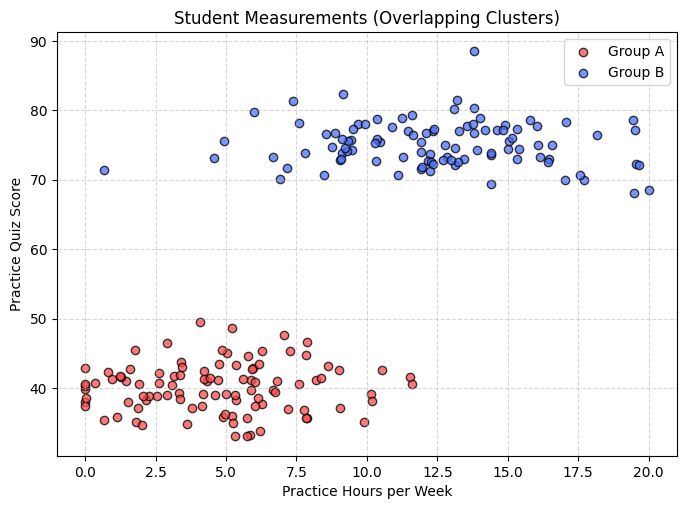

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

# Generate clusters with overlapping spread
np.random.seed(42)
X_raw, y_raw = make_blobs(
    n_samples=200,
    centers=[[5, 40], [12, 75]],
    cluster_std=[3.5, 3.5],
    random_state=42
)

# Ensure realistic ranges
X_raw[:, 0] = np.clip(X_raw[:, 0], 0, 20)      # Hours per week
X_raw[:, 1] = np.clip(X_raw[:, 1], 0, 100)     # Quiz score

plt.figure(figsize=(8, 5.5))
plt.scatter(X_raw[y_raw == 0, 0], X_raw[y_raw == 0, 1], color='#FF4B4B', label='Group A', alpha=0.75, edgecolors='k')
plt.scatter(X_raw[y_raw == 1, 0], X_raw[y_raw == 1, 1], color='#4B70FF', label='Group B', alpha=0.75, edgecolors='k')
plt.xlabel('Practice Hours per Week')
plt.ylabel('Practice Quiz Score')
plt.title('Student Measurements (Overlapping Clusters)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 2. How KNN Works: Finding the Closest K Points ($K=3$, $K=5$, $K=9$)
To prevent data leakage, we split our data into training and validation sets before applying any scaling transformation. We then find the nearest neighbors for a selected test point across different values of $K$.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

# Train-test split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42)

# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

# Choose a specific test student profile to query
test_idx = 4
query_raw = X_test_raw[test_idx].reshape(1, -1)
query_scaled = X_test[test_idx].reshape(1, -1)

# Find neighbor profiles for different K values
for k in [3, 5, 9]:
    nn = NearestNeighbors(n_neighbors=k)
    nn.fit(X_train)
    distances, indices = nn.kneighbors(query_scaled)

    print(f"\n--- Nearest Neighbors for K = {k} ---")
    print(f"Query Student: {query_raw[0, 0]:.1f} hours, {query_raw[0, 1]:.1f} score")
    for idx, (neighbor_idx, dist) in enumerate(zip(indices[0], distances[0])):
        neighbor_raw = X_train_raw[neighbor_idx]
        lbl = "Group A" if y_train[neighbor_idx] == 0 else "Group B"
        print(f"  Neighbor {idx+1}: ({neighbor_raw[0]:.1f} hrs, {neighbor_raw[1]:.1f} score) | Class: {lbl} | Dist: {dist:.3f}")


--- Nearest Neighbors for K = 3 ---
Query Student: 7.6 hours, 78.2 score
  Neighbor 1: (7.4 hrs, 81.4 score) | Class: Group B | Dist: 0.183
  Neighbor 2: (8.6 hrs, 76.6 score) | Class: Group B | Dist: 0.212
  Neighbor 3: (7.8 hrs, 73.8 score) | Class: Group B | Dist: 0.248

--- Nearest Neighbors for K = 5 ---
Query Student: 7.6 hours, 78.2 score
  Neighbor 1: (7.4 hrs, 81.4 score) | Class: Group B | Dist: 0.183
  Neighbor 2: (8.6 hrs, 76.6 score) | Class: Group B | Dist: 0.212
  Neighbor 3: (7.8 hrs, 73.8 score) | Class: Group B | Dist: 0.248
  Neighbor 4: (8.9 hrs, 76.7 score) | Class: Group B | Dist: 0.263
  Neighbor 5: (8.8 hrs, 74.8 score) | Class: Group B | Dist: 0.299

--- Nearest Neighbors for K = 9 ---
Query Student: 7.6 hours, 78.2 score
  Neighbor 1: (7.4 hrs, 81.4 score) | Class: Group B | Dist: 0.183
  Neighbor 2: (8.6 hrs, 76.6 score) | Class: Group B | Dist: 0.212
  Neighbor 3: (7.8 hrs, 73.8 score) | Class: Group B | Dist: 0.248
  Neighbor 4: (8.9 hrs, 76.7 score) | Cla

## 3. Decision Boundaries: Comparing Small vs. Large K
Different values of $K$ shift the bias-variance tradeoff.
- **Small $K$** (e.g., $K=1$): High variance, boundary is highly sensitive to noise.
- **Medium $K$** (e.g., $K=7$): Balances smooth boundaries with accuracy.
- **Large $K$** (e.g., $K=35$): High bias, overly smooth boundary that may underfit.

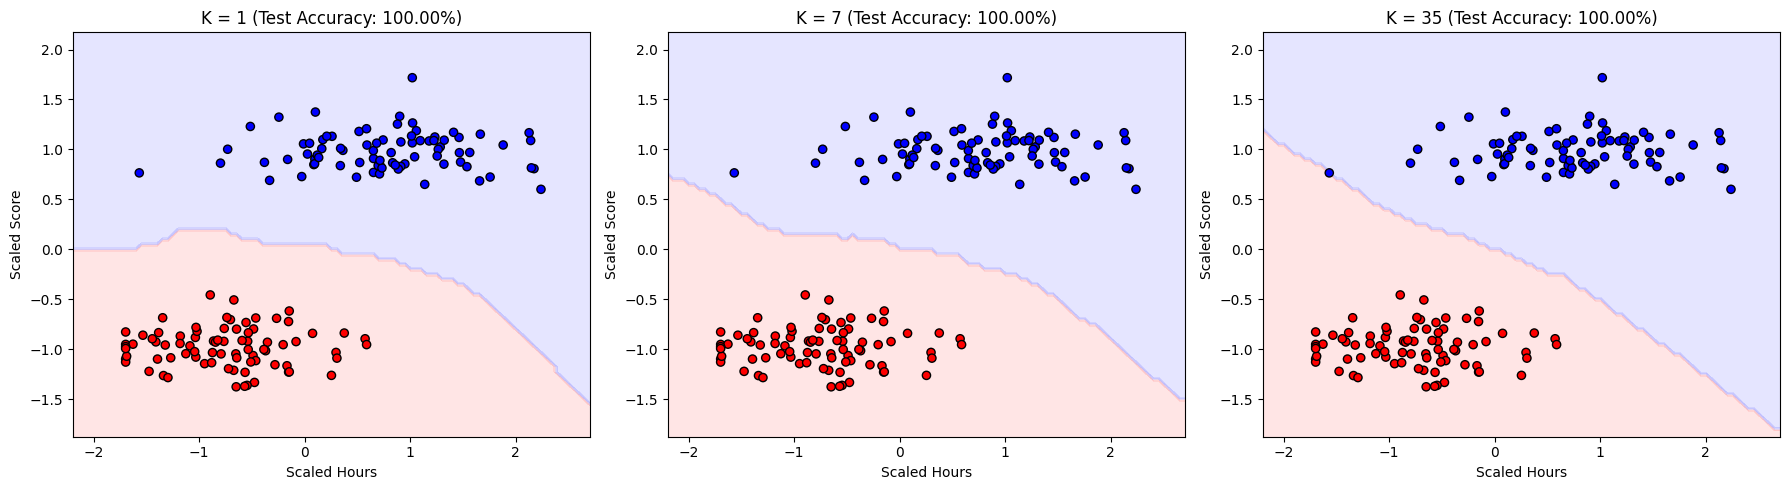

In [26]:
from sklearn.neighbors import KNeighborsClassifier
from matplotlib.colors import ListedColormap

# Define evaluation boundary points
x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))

cm_bg = ListedColormap(['#FFAAAA', '#AAAAFF'])
cm_pts = ListedColormap(['#FF0000', '#0000FF'])

k_boundaries = [1, 7, 35]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, k in zip(axes, k_boundaries):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)

    Z = knn.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=cm_bg)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_pts, edgecolors='k', s=35)

    test_acc = knn.score(X_test, y_test)
    ax.set_title(f'K = {k} (Test Accuracy: {test_acc:.2%})')
    ax.set_xlabel('Scaled Hours')
    ax.set_ylabel('Scaled Score')

plt.tight_layout()
plt.show()

## 4. Selecting K via Cross-Validation & Evaluating on Held-Out Test Set
We perform 5-fold Stratified Cross-Validation inside a Pipeline on the training set to choose the optimal $K$, then evaluate on the unseen test set.

Optimal K determined by Grid Search CV: 1


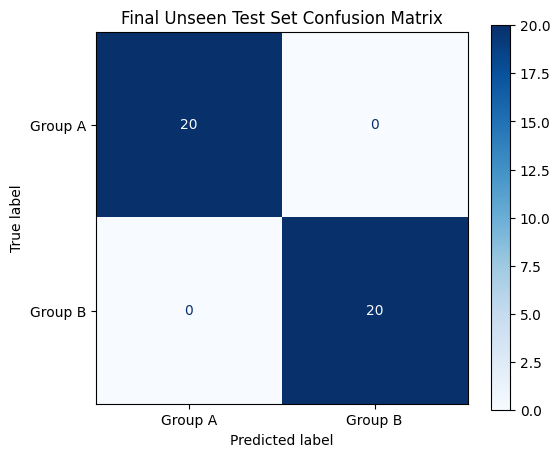

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

param_grid = {'knn__n_neighbors': np.arange(1, 25)}
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train_raw, y_train)

best_k = grid_search.best_params_['knn__n_neighbors']
print(f"Optimal K determined by Grid Search CV: {best_k}")

# Final Evaluation
final_model = grid_search.best_estimator_
y_pred = final_model.predict(X_test_raw)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=['Group A', 'Group B']).plot(cmap='Blues', ax=ax)
plt.title('Final Unseen Test Set Confusion Matrix')
plt.show()

### Understanding the Confusion Matrix Output
- **The Diagonal Elements**: Represent correct predictions. Top-left cell indicates the number of actual Group A students correctly predicted as Group A (True Negatives). Bottom-right cell represents actual Group B students correctly predicted as Group B (True Positives).
- **The Off-Diagonal Elements**: Represent errors/misclassifications. Top-right indicates Group A students predicted as Group B (Type I error). Bottom-left indicates Group B students predicted as Group A (Type II error), which are expected due to our high cluster overlap (`cluster_std=[3.5, 3.5]`).

## 5. Why Scaling Features Matters
When data has features with very different raw scales (e.g. 0-20 Hours vs 0-100 Quiz Scores), the feature with the larger absolute range dominates the distance calculation. Scaling ensures all features contribute proportionally.

In [28]:
# Fit on Unscaled Raw Inputs vs Standardized Inputs
knn_unscaled = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_raw, y_train)
knn_scaled = KNeighborsClassifier(n_neighbors=best_k).fit(X_train, y_train)

acc_unscaled = knn_unscaled.score(X_test_raw, y_test)
acc_scaled = knn_scaled.score(X_test, y_test)

print(f"Final Accuracy WITHOUT feature scaling: {acc_unscaled:.2%}")
print(f"Final Accuracy WITH feature scaling:    {acc_scaled:.2%}")

Final Accuracy WITHOUT feature scaling: 100.00%
Final Accuracy WITH feature scaling:    100.00%


## 6. KNN Regression: Predicting Continuous Targets
When predicting continuous values rather than discrete classes, KNN regression computes predictions by taking the average target value of neighboring points.

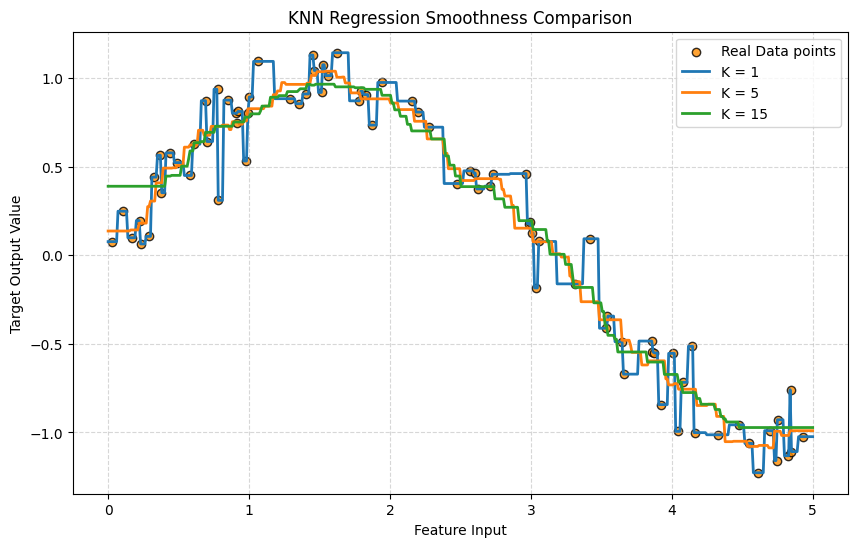

In [29]:
from sklearn.neighbors import KNeighborsRegressor

# Generate a continuous 1D regression mapping
np.random.seed(42)
X_reg = np.sort(5 * np.random.rand(80, 1), axis=0)
y_reg = np.sin(X_reg).ravel() + np.random.normal(0, 0.15, X_reg.shape[0])

T = np.linspace(0, 5, 500)[:, np.newaxis]

plt.figure(figsize=(10, 6))
plt.scatter(X_reg, y_reg, color='darkorange', label='Real Data points', alpha=0.8, edgecolors='k')

# Comparing smoothness across K = 1, 5, and 15
for k in [1, 5, 15]:
    knn_reg = KNeighborsRegressor(n_neighbors=k)
    y_pred_reg = knn_reg.fit(X_reg, y_reg).predict(T)
    plt.plot(T, y_pred_reg, label=f'K = {k}', linewidth=2)

plt.title('KNN Regression Smoothness Comparison')
plt.xlabel('Feature Input')
plt.ylabel('Target Output Value')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Smoothness Analysis in KNN Regression:
- **$K = 1$**: Highly jagged and step-like curve because it perfectly fits the closest individual data point (high variance, overfitting).
- **$K = 5$**: Moderately smooth; averages local variations while maintaining trend fidelity.
- **$K = 15$**: **The smoothest curve** of the three; by taking a larger average neighborhood, it filters out individual noise and produces a smooth, generalized wave.